# COU 07506 Digital Signal Processing: Week 04: z-Transform Laboratory: Poles, Zeros and Stability
Name: HOSANA HEREMAN KOMBA   
Registration No.: 240242445476
Class: BEng24COE-1            

Instructor: DR.HAJI FIMBOMBAYA

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio
plt.rcParams["figure.figsize"] = (9, 3.5)

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from IPython.display import Audio
plt.rcParams["figure.figsize"] = (9, 3.5)

## Pre-lab
(a) z^2 - 0.9z + 0.81 = 0 gives poles z = 0.45 ± j0.779, |p| = 0.9 < 1, so the system is stable.

(b) X(z) = 2/(1 - 0.5z^-1) - 1/(1 - 0.25z^-1)

## Task 4.1: A pole-zero plotting function

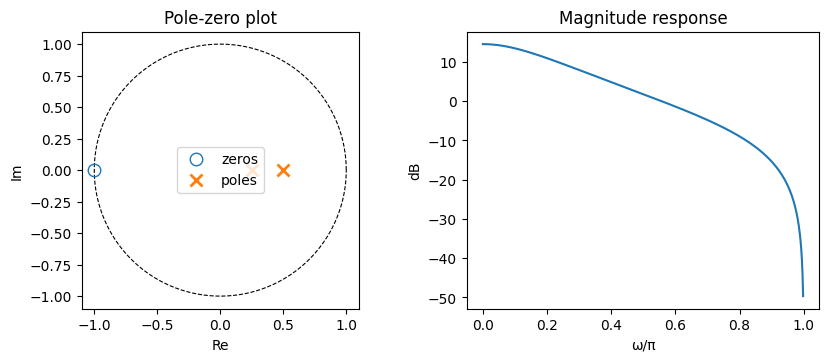

poles: [0.5  0.25]  stable: True


In [ ]:
def zplane(b, a, ax=None):
    z, p, k = signal.tf2zpk(b, a)
    ax = ax or plt.gca()
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), "k--", lw=0.8)
    ax.plot(z.real, z.imag, "o", mfc="none", ms=9, label="zeros")
    ax.plot(p.real, p.imag, "x", ms=9, mew=2, label="poles")
    ax.set_aspect("equal"); ax.legend(); ax.set_xlabel("Re"); ax.set_ylabel("Im")
    return z, p

b, a = [1, 1], [1, -0.75, 0.125]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6))
z, p = zplane(b, a, ax1)
ax1.set_title("Pole-zero plot")
w, H = signal.freqz(b, a, worN=512)
ax2.plot(w/np.pi, 20*np.log10(np.abs(H)))
ax2.set_title("Magnitude response"); ax2.set_xlabel("ω/π"); ax2.set_ylabel("dB")
plt.show()
print("poles:", p, " stable:", np.all(np.abs(p) < 1))

### Observations (Task 4.1)
H(z) = (1 + z^-1)/(1 - 0.75z^-1 + 0.125z^-2) has a zero at z = -1 and poles at z = 0.5 and z = 0.25. Both poles are inside the unit circle (|p| < 1), so the system is stable. The magnitude response falls steadily and drops to a deep null at ω = π, because of the zero at z = -1.

## Task 4.2: Inverse z-transform with residuez

In [ ]:
n = np.arange(10)
impulse = np.zeros(10); impulse[0] = 1

for bb in ([1], [1, 1]):
    r, p, k = signal.residuez(bb, [1, -0.75, 0.125])
    x_pf = sum(ri * pi**n for ri, pi in zip(r, p)).real
    x_lf = signal.lfilter(bb, [1, -0.75, 0.125], impulse)
    print("b =", bb, " residues", np.round(r, 3), " poles", p, " match:", np.allclose(x_pf, x_lf))

print(np.allclose(signal.lfilter([1, 1], [1, -0.75, 0.125], impulse), 6*0.5**n - 5*0.25**n))

b = [1]  residues [-1.  2.]  poles [0.25 0.5 ]  match: True
b = [1, 1]  residues [-5.  6.]  poles [0.25 0.5 ]  match: True
True


### Observations (Task 4.2)
For X(z) = 1/(1 - 0.75z^-1 + 0.125z^-2), residuez gave residues 2 and -1 at poles 0.5 and 0.25. This matches my pre-lab (b). For b = [1, 1] the residues are 6 and -5, so h(n) = 6(0.5)^n - 5(0.25)^n. The partial-fraction result matched lfilter (np.allclose gave True).

## Task 4.3: Pole position and the impulse response

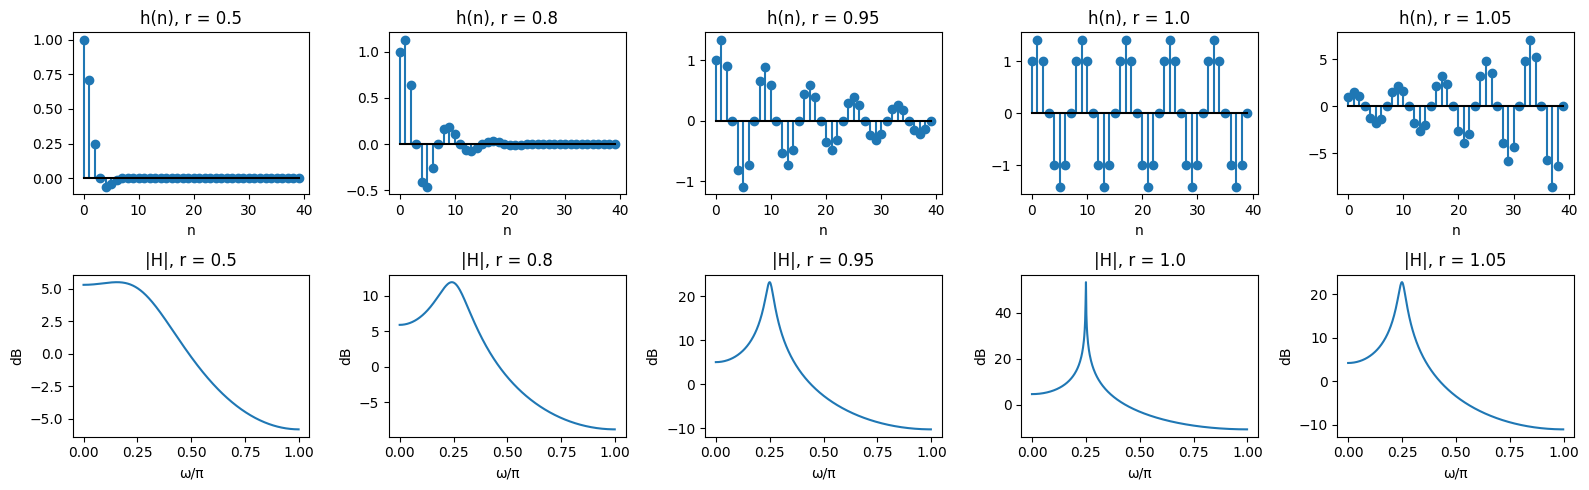

In [ ]:
imp = np.zeros(40); imp[0] = 1
fig, axes = plt.subplots(2, 5, figsize=(16, 5))
for i, r in enumerate([0.5, 0.8, 0.95, 1.0, 1.05]):
    A = [1, -2*r*np.cos(np.pi/4), r**2]
    h = signal.lfilter([1], A, imp)
    w, H = signal.freqz([1], A, worN=511)     # 511 avoids a divide-by-zero at r = 1
    axes[0, i].stem(h, basefmt="k-")
    axes[0, i].set_title(f"h(n), r = {r}"); axes[0, i].set_xlabel("n")
    axes[1, i].plot(w/np.pi, 20*np.log10(np.abs(H)))
    axes[1, i].set_title(f"|H|, r = {r}"); axes[1, i].set_xlabel("ω/π"); axes[1, i].set_ylabel("dB")
plt.tight_layout(); plt.show()

### Observations (Task 4.3)
Larger r means a slower decay and a sharper resonance peak at ω = π/4. At r = 1.0 h(n) oscillates forever (marginally stable), and at r = 1.05 it grows without bound (unstable). r = 0.5, 0.8 and 0.95 are stable.

## Task 4.4: Stability of given systems

H1: max|pole| = 0.943, max|h| in last 50 samples = 0.000236
H2: max|pole| = 2.000, max|h| in last 50 samples = 1.61e+60
H3: max|pole| = 1.000, max|h| in last 50 samples = 0.667
H4: max|pole| = 0.000, max|h| in last 50 samples = 0


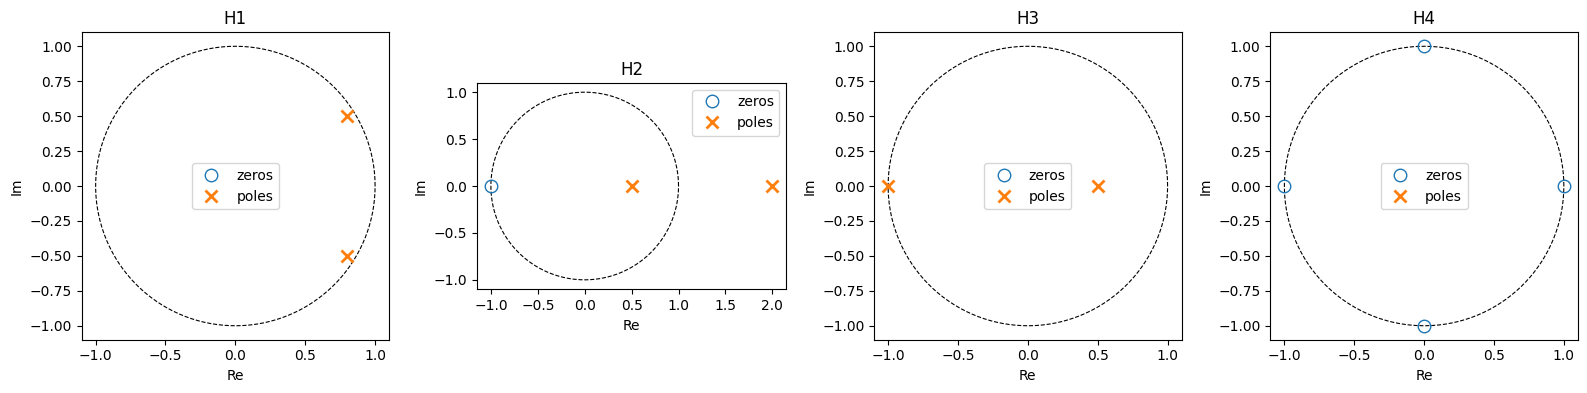

In [ ]:
systems = {"H1": ([1], [1, -1.6, 0.89]),
           "H2": ([1, 1], [1, -2.5, 1]),
           "H3": ([1], [1, 0.5, -0.5]),
           "H4": ([1, 0, 0, 0, -1], [1])}
imp = np.zeros(200); imp[0] = 1
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (name, (b, a)) in zip(axes, systems.items()):
    z, p = zplane(b, a, ax); ax.set_title(name)
    h = signal.lfilter(b, a, imp)
    pmax = np.max(np.abs(p)) if len(p) else 0
    print(f"{name}: max|pole| = {pmax:.3f}, max|h| in last 50 samples = {np.max(np.abs(h[-50:])):.3g}")
plt.tight_layout(); plt.show()

### Observations (Task 4.4)
- H1: poles inside the unit circle (max radius 0.943). Stable, h(n) decays.
- H2: a pole at radius 2.0, outside the unit circle. Unstable, h(n) grows.
- H3: a pole at z = -1, on the unit circle. Marginally stable, h(n) does not decay.
- H4: an FIR filter (all poles at z = 0). Always stable.
The classification from the pole plots agreed with the behaviour of h(n).

## Task 4.5: Design a resonator

fs, f0, r = 8000, 1000, 0.97
th = 2*np.pi*f0/fs                          # = π/4
a = [1, -2*r*np.cos(th), r**2]              # poles r e^{±jθ}
b = np.array([1, 0, -1], float)             # zeros at z = +1 and -1
w, H = signal.freqz(b, a, worN=2048, fs=fs)
b = b / np.max(np.abs(H))                   # normalise the peak gain to 0 dB
w, H = signal.freqz(b, a, worN=2048, fs=fs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
zplane(b, a, ax1); ax1.set_title("Pole-zero plot")
ax2.plot(w, 20*np.log10(np.abs(H) + 1e-12))
ax2.set_ylim(-60, 5); ax2.set_title("Resonator response")
ax2.set_xlabel("frequency (Hz)"); ax2.set_ylabel("dB")
plt.show()

rng = np.random.default_rng(0)
y = signal.lfilter(b, a, rng.standard_normal(2*fs))
y = y / np.max(np.abs(y))
display(Audio(y, rate=fs))

### Observations (Task 4.5)
With poles at 0.97 e^(±jπ/4) and zeros at z = ±1, the filter peaks at 1000 Hz and has nulls at 0 Hz and 4000 Hz (fs/2). It works as a narrow band-pass filter. White noise passed through it sounds like: ... (write what you heard).

## Analysis questions

1. As r goes toward 1, the poles approach the unit circle, so the resonance becomes narrower (bandwidth is about 2(1 - r) rad/sample) and the ringing lasts longer.

2. h(n) does not decay: it keeps oscillating forever (or stays constant if the pole is at z = 1). The system is marginally stable and not BIBO stable.

3. The zeros at z = 1 and z = -1 give nulls at 0 Hz and fs/2. With the pole resonance at 1 kHz in between, only a band around 1 kHz passes, so it is a band-pass filter.

4. For A(z) = 1 + a1 z^-1 + a2 z^-2, stability needs |a2| < 1 and |a1| < 1 + a2.
(a) a2 = 0.89 and |a1| = 1.6 < 1.89: stable.
(b) a2 = 1 fails |a2| < 1: unstable.
(c) |a1| = 0.5 equals 1 + a2 = 0.5, so it is on the boundary: marginal (pole at -1).
These agree with Task 4.4.

## AI-use statement
AI tools used: Gemini
Used for: Explaining the tasks, generating pole-zero plots, evaluating system stability, and verifying residue calculations.
How I verified: Checked pole radii numerically, compared residues with manual calculations, verified stability criteria using impulse responses, and listened to the filtered resonator audio output.
I confirm that understand and can explain all submitted code.